In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from env import PWEnv
env = PWEnv()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


0.5 0.8
4 6 2


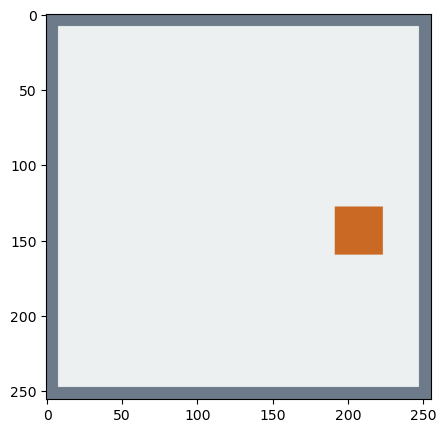

0.5585270966048385 0.7942355841209692
4 6 2
0.6148050297095269 0.7771638597533861
4 6 2
0.6666710699058807 0.7494408836907636
5 5 2
0.7121320343559643 0.7121320343559643
5 5 2


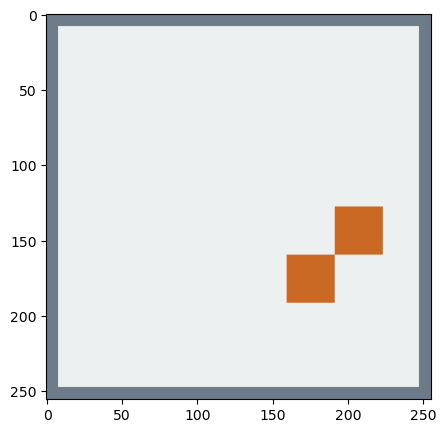

0.7494408836907636 0.6666710699058807
5 5 2
0.7771638597533861 0.6148050297095269
6 4 2
0.7942355841209692 0.5585270966048385
6 4 2
0.8 0.5
6 4 2


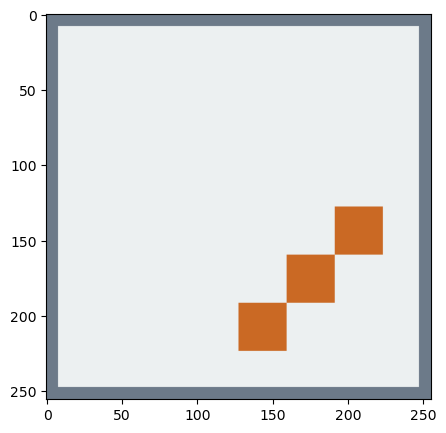

0.7942355841209692 0.44147290339516154
6 3 2
0.7771638597533861 0.3851949702904731
6 3 2
0.7494408836907636 0.33332893009411946
5 2 2
0.7121320343559643 0.2878679656440358
5 2 2


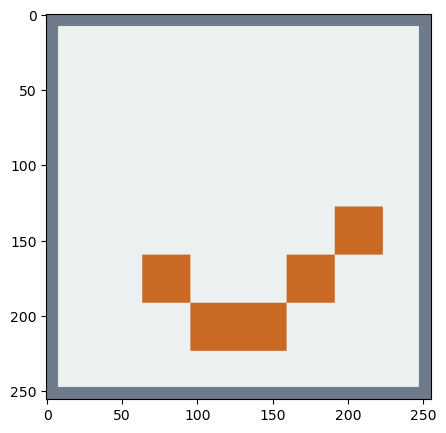

0.6666710699058807 0.25055911630923644
5 2 2
0.614805029709527 0.22283614024661397
4 1 2
0.5585270966048386 0.20576441587903088
4 1 2
0.5 0.2
4 1 2


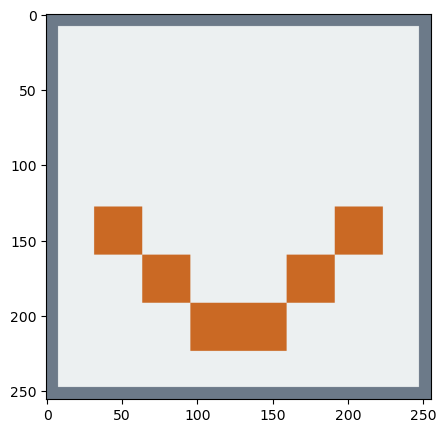

0.4414729033951615 0.20576441587903088
3 1 2
0.3851949702904731 0.22283614024661397
3 1 2
0.33332893009411946 0.2505591163092364
2 2 2
0.2878679656440358 0.2878679656440357
2 2 2


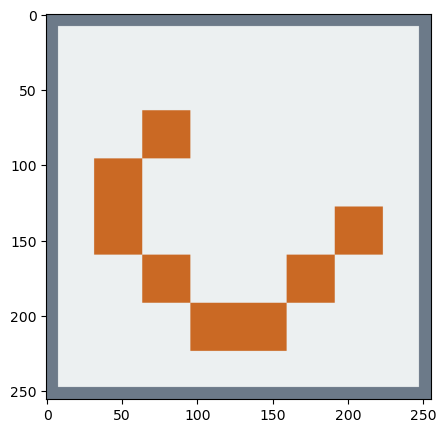

0.25055911630923644 0.33332893009411935
2 2 2
0.22283614024661408 0.3851949702904729
1 3 2
0.20576441587903094 0.44147290339516143
1 3 2
0.2 0.49999999999999994
1 3 2


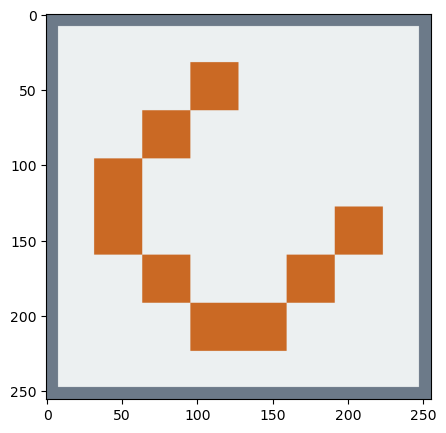

0.20576441587903088 0.5585270966048385
1 4 2
0.22283614024661402 0.614805029709527
1 4 2
0.2505591163092364 0.6666710699058805
2 5 2
0.2878679656440357 0.7121320343559642
2 5 2


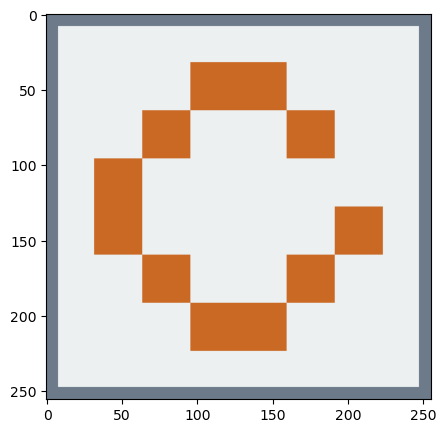

0.33332893009411935 0.7494408836907636
2 5 2
0.3851949702904729 0.7771638597533859
3 6 2
0.4414729033951614 0.7942355841209691
3 6 2
0.49999999999999994 0.8
3 6 2


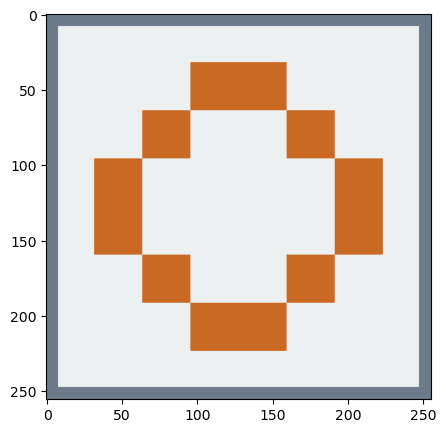

0.5585270966048385 0.7942355841209692
4 6 2
0.614805029709527 0.7771638597533861
4 6 2
0.6666710699058805 0.7494408836907636
5 5 2
0.7121320343559642 0.7121320343559643
5 5 2


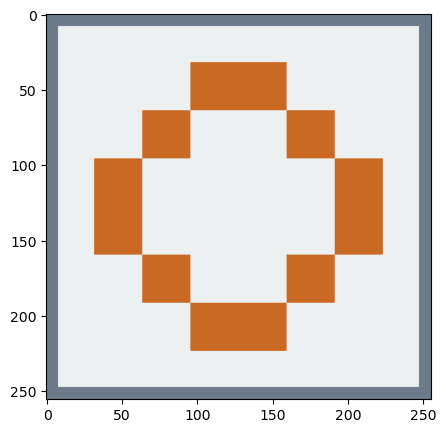

0.7494408836907636 0.6666710699058807
5 5 2
0.7771638597533859 0.6148050297095271
6 4 2
0.7942355841209691 0.5585270966048387
6 4 2
0.8 0.5000000000000001
6 4 2


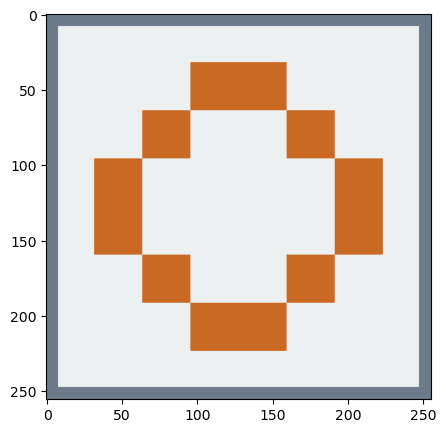

0.7942355841209692 0.4414729033951618
6 3 2
0.7771638597533861 0.385194970290473
6 3 2
0.7494408836907637 0.33332893009411946
5 2 2
0.7121320343559645 0.287867965644036
5 2 2


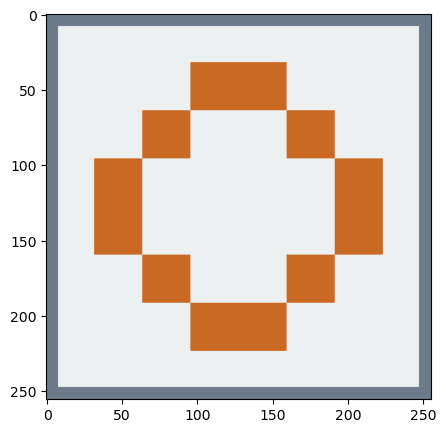

0.6666710699058807 0.25055911630923644
5 2 2
0.6148050297095271 0.22283614024661408
4 1 2
0.5585270966048383 0.20576441587903083
4 1 2
0.5000000000000001 0.2
4 1 2


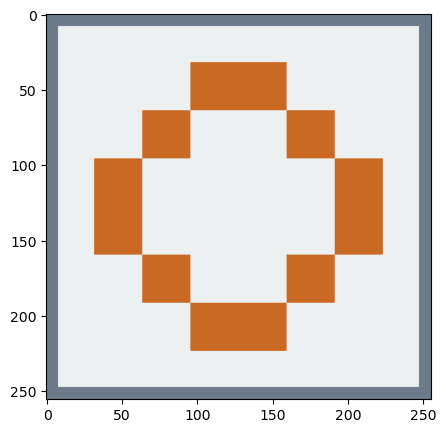

0.4414729033951618 0.20576441587903083
3 1 2
0.38519497029047306 0.22283614024661397
3 1 2
0.33332893009411946 0.25055911630923633
2 2 2
0.2878679656440356 0.28786796564403583
2 2 2


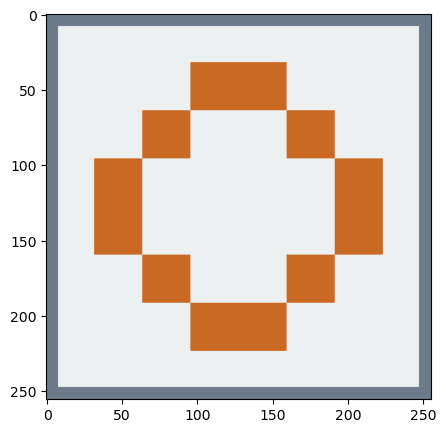

0.25055911630923644 0.3333289300941193
2 2 2
0.22283614024661408 0.38519497029047284
1 3 2
0.20576441587903083 0.4414729033951616
1 3 2
0.2 0.4999999999999999
1 3 2


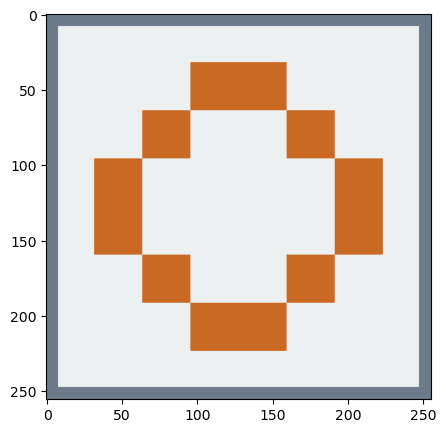

0.20576441587903083 0.5585270966048381
1 4 2
0.22283614024661397 0.6148050297095269
1 4 2
0.25055911630923633 0.6666710699058804
2 5 2
0.2878679656440355 0.712132034355964
2 5 2


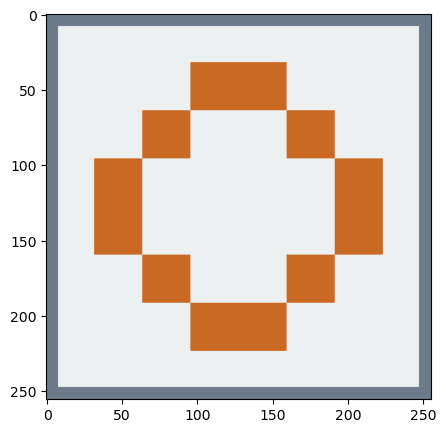

0.3333289300941193 0.7494408836907636
2 5 2
0.38519497029047284 0.7771638597533859
3 6 2
0.4414729033951616 0.7942355841209692
3 6 2


In [19]:
# Example that scripts an agent to draw a circle.

def policy(i):
    x = 0.5 + 0.3 * np.cos(i * (1/32.0) * 2 * np.pi)
    y = 0.5 + 0.3 * np.sin(i * (1/32.0) * 2 * np.pi)
    x_id = int(np.clip(np.floor(x * 8), 0, 7))
    y_id = int(np.clip(np.floor(y * 8), 0, 7))

    elem_id = 2 # Wood
    print(y, x)
    print(y_id, x_id, elem_id)
    action = np.ravel_multi_index([y_id, x_id, elem_id], (8, 8, len(env.elems)))
    return action

ob_list = []
ac_list = []
ob, _ = env.reset()
ob_list.append(ob)
for i in range(64):
    ac = policy(i)
    ob, reward, done, truncated, _ = env.step(ac)
    if i % 4 == 0:
        im = env.render()
        fig, axs = plt.subplots(1, figsize=(5, 5))
        axs.imshow(im)
        plt.show()
    ob_list.append(ob)
    ac_list.append(ac)

# Save as offline data, etc...